<a href="https://colab.research.google.com/github/CIS5190/cis-4190-5190-fall-26/blob/main/hw1/hw1_skeleton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CIS 4190/5190 Fall 2026 - Homework 1**

# **Tips for Coding Homeworks**
Dear class, here are some tips to follow in coding HWs in this class, to minimize the chances of hitting hard-to-resolve bugs:

1.   **Do not set/alter the random seeds we provide.** (Seeds fixed in setup or "don't change this line" cells exist so that everyone's numbers, and the hidden autograder tests, match up.)
2.   Most bugs come down to minor errors in your code. The hardest and most important part of coding is debugging; debugging ML code is a key skillset you should acquire in this class.
3.   Good python coding avoids loops if at all possible: in particular, **for any vector and matrix operations, use `numpy` functions instead of loops**. This will often speed up your code by orders of magnitude. You may also want to take a look at the [python primer](https://www.engineering.upenn.edu/~cis5190/fall2026/docs/basics_python_numpy.ipynb).
4.   Pay **extra attention to "copying" vs "moving" objects** i.e. take care during assignment operations. Otherwise, it may lead to incorrect results or Out Of Memory issues and Colab notebook restarts.
5.   If you are running into a `'__builtins__'` error, it's likely because you're using a function call of the form `numpy.ndarray.mean()`, like `a.mean()`. This is technically correct, but our autograding software PennGrader can't handle it. Please use the function **call `numpy.mean(a)` instead.**
6.   For this homework especially, pay **special attention to** the `compute_gradient` function and the `fit` function of the **Linear regression** section, as these involve multiple key concepts that also come back in Logistic Regression.

Have fun coding up and training your first ML algorithms!

> **Important: Save a Copy Before Starting**
> Please click *“Copy to Drive”* in the top menu bar or go to *File → Save a Copy in Drive*.
> This shared copy is read-only, so any edits you make to it will not be saved. Work in your
> own copy.

---

> **Points**
> This assignment is worth **50 points**: 45 points that every student completes, plus 5
> points marked **[5190 Extra]**, which are all of section 1.1.6: stochastic gradient
> descent, and predicting from an SGD-trained model.
>
> - **CIS 4190** is graded out of **45**. The [5190 Extra] parts are optional for you.
> - **CIS 5190** is graded out of **50**. The [5190 Extra] parts are required for you.
>
> CIS 4190 students are welcome to attempt the [5190 Extra] parts for credit, but your total
> for this assignment is still capped at 45 points.


## Setup Cell 1: Imports and Configuration

This cell imports essential libraries you will need for this assignment. It also disables Pandas' chained assignment warnings to reduce clutter in your output.

*Note:* Only import libraries when you need them to keep your notebook clean. Additional imports will be added as the assignment progresses.

In [26]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.linalg import *

# Suppress pandas chained assignment warnings for cleaner output
pd.options.mode.chained_assignment = None

np.random.seed(42)  # don't change this line!!
random.seed(42)     # don't change this line!!

## Setup Cell 2: Environment Detection

This cell installs the `dill` package (used to retrieve source code) and detects whether the notebook is running in Google Colab or the autograder environment.

- `NOTEBOOK` will be `True` if running in Colab and `False` in the autograder.
- This check helps your code run correctly depending on the environment.
- Do **not** modify this cell.

In [27]:
# For autograder only, do not modify this cell.
# Determines if code is running in Google Colab or autograder environment

!pip install dill
from dill.source import getsource

NOTEBOOK = (os.getenv('IS_AUTOGRADER') is None)

if NOTEBOOK:
    print("[INFO, OK] Google Colab.")
else:
    print("[INFO, OK] Autograder.")

[INFO, OK] Google Colab.


## PennGrader Setup

As in HW0, you'll use PennGrader to get instant feedback on your answers. You may resubmit each grading
cell up to 100 times per day.

**Your most recent submission for each grading cell is the one that counts** — re-running a
grading cell with a worse answer will lower your recorded score.

Because Part 1 asks you to submit an entire `LinearRegression` **class** (not just one
function), we need one extra helper cell below (`grader_serialize`) that knows how to pull the
full class definition out of your notebook so PennGrader can grade it.

In [28]:
%%capture
!pip3 install penngrader-client==0.5.13

In [29]:
from penngrader.grader import *

### Class-serialization helper

This cell lets PennGrader retrieve the full source of a **class** you define in a cell above
(needed for grading `LinearRegression` in Part 1). Do **not** modify this cell.

In [30]:
# For autograder only, do not modify this cell.
# Lets PennGrader retrieve the full source of a class defined in an earlier cell.

import inspect, sys
from IPython.core.magics.code import extract_symbols

def new_getfile(object, _old_getfile=inspect.getfile):
    if not inspect.isclass(object):
        return _old_getfile(object)

    # Lookup by parent module (as in current inspect)
    if hasattr(object, '__module__'):
        object_ = sys.modules.get(object.__module__)
        if hasattr(object_, '__file__'):
            return object_.__file__

    # If parent module is __main__, lookup by methods
    for name, member in inspect.getmembers(object):
        if inspect.isfunction(member) and object.__qualname__ + '.' + member.__name__ == member.__qualname__:
            return inspect.getfile(member)
    else:
        raise TypeError('Source for {!r} not found'.format(object))
inspect.getfile = new_getfile

def grader_serialize(obj):
    cell_code = "".join(inspect.linecache.getlines(new_getfile(obj)))
    class_code = extract_symbols(cell_code, obj.__name__)[0][0]
    return class_code

### Autograder Setup

Please enter your **8-digit PennID** in the cell below:

In [31]:
# PLEASE ENSURE YOUR PENN-ID IS ENTERED CORRECTLY.
# IF NOT, THE AUTOGRADER WON'T KNOW WHO TO ASSIGN POINTS TO IN OUR BACKEND.

STUDENT_ID = 12345678          # YOUR PENN-ID GOES HERE AS AN INTEGER

## Initialize the Autograder

Run the following cell to initialize the autograder. This autograder will let you submit your code directly from this notebook and immediately receive a score.

**NOTE:** We store your submissions and check them against other students' submissions. So, not that you would, but please do **not** cheat.

In [32]:
%%writefile notebook-config.yaml

grader_api_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/TestSandbox"
grader_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"
token_generator_url: "https://yj0vsrf8l4.execute-api.us-east-1.amazonaws.com/Initial/GetTokens"
token_generator_api_key: "dBB5ucuV5L6GyKFKmlrfP4bKkhtnA0bP42lR3rSh"


Overwriting notebook-config.yaml


In [33]:
COURSE_NAME = 'cis5190_fall2026'
HOMEWORK_NUMBER = 1   # -> homework ID cis5190_fall2026_HW1

grader = PennGrader('notebook-config.yaml', HOMEWORK_NUMBER, STUDENT_ID, STUDENT_ID, COURSE_NAME)

PennGrader initialized with Student ID: 12345678

Make sure this correct or we will not be able to store your grade


# **1. Linear Regression [28 pts — 23 for CIS 4190]**

## **1.1. Linear Regression Implementation [18 pts — 13 for CIS 4190, Autograded]**

In this section you will implement linear regression with both L1 and L2 regularization. Your class LinearRegression must implement the following API:

* `__init__(alpha, tol, max_iter, beta_init, penalty, lambd)`
* `compute_cost(beta, X, y)`
* `compute_gradient(beta, X, y)`
* `fit(X, y)`
* `fit_sgd(X, y, random_state)` — **[5190 Extra]**
* `has_converged(beta_old, beta_new)`
* `predict(X)`

Note that these methods have already been declared for you (with the correct signatures) in the LinearRegression class below. **DO NOT** change the API.

You must implement these yourself with `numpy`. Do not use `sklearn` (or any other library that fits a linear model for you) inside the class. You are welcome to use `sklearn` afterwards to check your own results.

### **1.1.1. Cost Function [3 pts]**

The `compute_cost` function should compute the cost for a given $\beta$ vector. The cost is a scalar value given by:

$
L({\beta}) = \frac{1}{N}\sum_{i =1}^N (f_{{\beta}}({x}_i) - y_i)^2
$

where

> $f_{{\beta}}({x}_i) = \beta^Tx_i$

Based on the regularization penalty, you may need to add below regularization penalty loss to MSE Loss computed previously.

L1 Regularization Loss:
>$
L_1({\beta}) = L({\beta}) + \lambda\sum_{j = 1}^D  |{\beta}_j|
$

L2 Regularization Loss:
>$
L_2({\beta}) = L({\beta}) + \lambda\sum_{j = 1}^D  {\beta}_j^2
$

$N$ is the number of training samples and $D$ is the number of features (excluding the intercept term). $\beta$ is a $D + 1$ dimensional vector, with the first element being the intercept term. **Note that we do not include the intercept in the regularization terms** (i.e. `beta[0]` is always excluded from the penalty, regardless of whether the `X` you're passed already has a leading column of ones).

---

### **1.1.2. Gradient of the Cost Function [3 pts]**

The `compute_gradient` function should compute the gradient of the cost function at a given $\beta$.

**Deriving it is part of the exercise** — unlike the cost above, the formula is not given to
you. Differentiate $L({\beta})$, $L_1({\beta})$ and $L_2({\beta})$ from 1.1.1 with respect to
$\beta$, and remember that the intercept $\beta_0$ is excluded from the penalty in the cost,
so it must be excluded from the penalty's derivative too.

---

### **1.1.3. Convergence Check [2 pts]**

The `has_converged` function should return whether gradient descent algorithm has converged or not. Refer to the below section 1.1.4 for the convergence condition.

---

### **1.1.4. Training with Gradient Descent [4 pts]**

The `fit` method should train the model via gradient descent, relying on the cost and gradient functions. The trained weights/coefficients must be stored as `beta_`. The weights and the corresponding cost after every gradient descent iteration must be stored in `hist_beta_` and `hist_cost_` respectively.

* The gradient descent stops or converges when $\beta$ stops changing or changes negligibly between consecutive iterations; i.e., when
$\| {\beta}_\mathit{new} -  {\beta}_\mathit{old} \|_2 \leq \epsilon$,
for some small $\epsilon$ (e.g., $\epsilon$ = 1E-4). $\epsilon$ is stored as `tol` (short for tolerance).

* To ensure that the function terminates, you should set a maximum limit for the number of epochs, irrespective of whether $\beta$ converges or not. The limit is stored as `max_iter`.

* `alpha` is the learning rate of the gradient descent algorithm.

---

### **1.1.5. Predict [1 pt]**

The `predict` function should predict outputs given an input data matrix by applying the coefficient matrix.

---

### **1.1.6. Training with Stochastic Gradient Descent (SGD) [5190 Extra, 5 pts]**

The `fit_sgd` method should train the model via stochastic gradient descent (SGD), relying on the cost and gradient functions.

The trained weights/coefficients must be stored as `beta_`. The weights and the corresponding cost after every SGD iteration must be stored in `hist_beta_` and `hist_cost_` respectively.

* Unlike regular (or batch) gradient descent, SGD takes a gradient step on a single training example on each iteration. In other words, rather than compute the gradient for all training examples, summing them, and taking a single gradient step, it iterates through training examples one by one, computing the gradient and performing a step for each. One pass over the entire training dataset is called an epoch; at the end of an epoch, the next epoch restarts from the first example in the training dataset.

* As with gradient descent, SGD stops or converges when $\beta$ stops changing or changes negligibly between consecutive **epochs** (not consecutive single-example steps), i.e., when
$\| {\beta}_\mathit{new} -  {\beta}_\mathit{old} \|_2 \leq \epsilon$,
comparing $\beta$ at the start and end of an epoch. $\epsilon$ is stored as `tol` (short for tolerance). Since each individual step is much smaller, SGD typically only checks for convergence at the **end of each epoch**.

* To ensure that the function terminates, you should set a maximum limit for the number of epochs, irrespective of whether $\beta$ converges or not. The limit is stored as `max_iter`.

* `alpha` is the learning rate of the SGD algorithm.

* Use `rng.permutation(N)` (where `rng = np.random.default_rng(random_state)`) to shuffle the order of examples within each epoch.

---

The two grading cells for this section check `fit_sgd` (4 pts) and `predict` on an SGD-trained model (1 pt).

---

Your implementation of the Linear Regression algorithm should closely follow the workflow described in the diagram below:

```plaintext
            ┌─────────────────────────────────────────────┐
            │                   init                      │
            │ (alpha, beta, max_iter, tol, penalty, lambd,│
            │            hist_cost_, hist_beta_)          │
            └────────────────────┬────────────────────────┘
                                 │
                                 ▼
                    ┌────────────────────────┐
                    │ Choose training entry  │
                    │ point                  │
                    └────────────┬───────────┘
                                 │
                ┌────────────────┘───────────────┐
                ▼                                ▼
 ┌─────────────────────────────┐     ┌──────────────────────────────┐
 │ fit()                       │     │ fit_sgd()                    │
 │ (Batch Gradient Descent)    │     │ (Stochastic Gradient Descent)│
 └───────────────┬─────────────┘     └───────────────┬──────────────┘
                 │                                   │
                 ▼                                   ▼
 ┌───────────────────────────┐     ┌────────────────────────────────┐
 │ Loop per-dataset averaged:│     │ Loop per-sample/epoch:         │
 │ - compute_gradient()      │     │ - compute_gradient()           │
 │ - compute_cost()          │     │ - compute_cost()               │
 │ - has_converged()?        │     │ - has_converged()?             │
 └───────────────┬───────────┘     └───────────────┬────────────────┘
                 │                                 │
                 └───────────────┬─────────────────┘
                                 ▼
                      ┌─────────────────────┐
                      │ predict (Inference) │
                      └─────────────────────┘

```
---

In [34]:
class LinearRegression:

    """
    Linear Regression

    Parameters
    ----------
    alpha: float, default=0.01
        Learning rate
    tol: float, default=0.0001
        Tolerance for stopping criteria
    max_iter: int, default=100
        Maximum number of iterations of gradient descent
    beta_init: None (or) numpy.ndarray of shape (D + 1,)
        The initial weights; if None, all weights will be zero by default
    penalty: string, default = None
        The type of regularization if any. The other options are l1 and l2
    lambd: float, default = 0
        The parameter regularization constant (i.e. lambda)

    Attributes
    ----------
    beta_: numpy.ndarray of shape (D + 1,)
        The value of the coefficients after gradient descent has converged
        or the number of iterations hit the maximum limit
    hist_beta_: numpy.ndarray of shape (num_iter, D + 1) where num_iter is the number of gradient descent iterations
        Stores beta_ after every gradient descent iteration
    hist_cost_: numpy.ndarray of shape (num_iter,) where num_iter is the number of gradient descent iterations
        Stores cost after every gradient descent iteration
    """

    def __init__(self, alpha = 0.01, tol=1e-4, max_iter = 100, beta_init = None, penalty = None, lambd = 0):

        # store metadata
        self.alpha = alpha
        self.beta_init = beta_init
        self.max_iter = max_iter
        self.tol = tol
        self.penalty = penalty
        self.lambd = lambd

        self.beta_ = None
        self.hist_cost_ = None
        self.hist_beta_ = None

    def compute_cost(self, beta, X, y):

        """
        Compute the cost/objective function with penalty if any.

        Parameters
        ----------
        beta: numpy.ndarray of shape (D + 1,)
            The coefficients
        X: numpy.ndarray of shape (N, D + 1)
            The input features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        cost: float
            The cost as a scalar value
        """

        # Complete the function (should account for three cases - no penalty, l1 penalty, and l2 penalty)
        # STUDENT TODO START:
        cost = np.mean((X @ beta - y) ** 2)
        if self.penalty == "l1":
            cost += self.lambd * np.sum(np.abs(beta[1:]))
        elif self.penalty == "l2":
            cost += self.lambd * np.sum(beta[1:] ** 2)
        return float(cost)
        # STUDENT TODO END

    def compute_gradient(self, beta, X, y):

        """
        Compute the gradient of the cost function with penalty if any.

        Parameters
        ----------
        beta: numpy.ndarray of shape (D + 1,)
            The coefficients
        X: numpy.ndarray of shape (N, D + 1)
            The input features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        gradient: numpy.ndarray of shape (D + 1,)
            The gradient values
        """

        # Complete the function (should account for three cases - no penalty, l1 penalty, and l2 penalty)
        # STUDENT TODO START:
        gradient = (2 / X.shape[0]) * (X.T @ (X @ beta - y))
        if self.penalty == "l1":
            gradient[1:] += self.lambd * np.sign(beta[1:])
        elif self.penalty == "l2":
            gradient[1:] += 2 * self.lambd * beta[1:]
        return gradient
        # STUDENT TODO END

    def has_converged(self, beta_old, beta_new):

        """
        Return whether gradient descent has converged.

        Parameters
        ----------
        beta_old: numpy.ndarray of shape (D + 1,)
            The weights prior to the update by gradient descent
        beta_new: numpy.ndarray of shape (D + 1,)
            The weights after the update by gradient descent

        Returns
        -------
        converged: bool
            Whether gradient descent converged or not
        """

        # Complete the function
        # STUDENT TODO START:
        return bool(np.linalg.norm(beta_new - beta_old) <= self.tol)
        # STUDENT TODO END

    def fit(self, X, y):

        """
        Compute the coefficients using gradient descent and store them as beta_.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The input features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        Nothing
        """

        N, D = X.shape

        # Adding a column of ones at the beginning for the bias term
        ones_col = np.ones((N, 1))
        X = np.hstack((ones_col, X))

        # Initializing the weights
        if self.beta_init is None:
            beta_old = np.zeros((D + 1,))
        else:
            beta_old = self.beta_init

        # Initializing the historical weights matrix
        # Remember to append this matrix with the weights after every gradient descent iteration
        self.hist_beta_ = np.array([beta_old])

        # Computing the cost for the initial weights
        cost = self.compute_cost(beta_old, X, y)

        # Initializing the historical cost array
        # Remember to append this array with the cost after every gradient descent iteration
        self.hist_cost_ = np.array([cost])

        # Complete the function
        # STUDENT TODO START:
        weights = [beta_old.copy()]
        costs = [cost]
        for _ in range(self.max_iter):
            beta_new = beta_old - self.alpha * self.compute_gradient(beta_old, X, y)
            weights.append(beta_new.copy())
            costs.append(self.compute_cost(beta_new, X, y))
            converged = self.has_converged(beta_old, beta_new)
            beta_old = beta_new
            if converged:
                break
        self.beta_ = beta_old.copy()
        self.hist_beta_ = np.array(weights)
        self.hist_cost_ = np.array(costs)
        # STUDENT TODO END

    def fit_sgd(self, X, y, random_state=None):

        """
        [5190 Extra] Compute the coefficients using Stochastic Gradient Descent
        and store them as beta_. CIS 4190 students may leave this one unimplemented;
        do not delete it, as the whole class is submitted together.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The input features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array
        random_state: int or None, default=None
            Seed for the shuffle. Shuffle the examples at the start of each epoch
            with `rng.permutation(N)`, where `rng = np.random.default_rng(random_state)`,
            so that a given seed always produces the same sequence of updates.

        Returns
        -------
        Nothing
        """

        N, D = X.shape

        # Adding a column of ones at the beginning for the bias term
        ones_col = np.ones((N, 1))
        X = np.hstack((ones_col, X))

        # Initializing the weights
        if self.beta_init is None:
            beta_old = np.zeros((D + 1,))
        else:
            beta_old = self.beta_init

        # Initializing the historical weights matrix
        # Remember to append this matrix with the weights after every gradient descent iteration
        self.hist_beta_ = np.array([beta_old])

        # Computing the cost for the initial weights
        cost = self.compute_cost(beta_old, X, y)

        # Initializing the historical cost array
        # Remember to append this array with the cost after every gradient descent iteration
        self.hist_cost_ = np.array([cost])

        # Init RNG, use it for shuffle
        if random_state is None:
            rng = np.random.default_rng()
        else:
            rng = np.random.default_rng(int(random_state))

        # Please use rng.permutation(N) for shuffle.
        # Remember: check for convergence only at the END of each epoch (comparing beta
        # at the start vs. end of that epoch), not after every single-example step.
        # Complete the function
        # STUDENT TODO START:
        weights = [beta_old.copy()]
        costs = [cost]
        for _ in range(self.max_iter):
            beta_epoch_start = beta_old.copy()
            for i in rng.permutation(N):
                gradient = self.compute_gradient(beta_old, X[i:i + 1], y[i:i + 1])
                beta_old = beta_old - self.alpha * gradient
                weights.append(beta_old.copy())
                costs.append(self.compute_cost(beta_old, X, y))
            if self.has_converged(beta_epoch_start, beta_old):
                break
        self.beta_ = beta_old.copy()
        self.hist_beta_ = np.array(weights)
        self.hist_cost_ = np.array(costs)
        # STUDENT TODO END

    def predict(self, X):

        """
        Predict the target variable values for the data points in X.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The input features matrix

        Returns
        -------
        y_hat: numpy.ndarray of shape (N,)
            The predicted target variables values for the data points in X
        """

        N = X.shape[0]
        X = np.hstack((np.ones((N, 1)), X))

        # Complete the function
        # STUDENT TODO START:
        return X @ self.beta_
        # STUDENT TODO END

In [35]:
def test_lin_reg_compute_cost(StudentLinearRegression):

    test_case_beta = np.array([ 1.62434536, -0.61175641])
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])

    student_lr_reg = StudentLinearRegression()
    student_ans = student_lr_reg.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 4.881828654157736

    assert np.abs(student_ans - required_ans) <= 1e-2

    student_lr_reg = StudentLinearRegression(penalty="l1", lambd=0.1)
    student_ans = student_lr_reg.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 4.94300429515773

    assert np.abs(student_ans - required_ans) <= 1e-2

    student_lr_reg = StudentLinearRegression(penalty="l2", lambd=0.1)
    student_ans = student_lr_reg.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 4.919253244675344
    assert np.abs(student_ans - required_ans) <= 1e-2

test_lin_reg_compute_cost(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [36]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_compute_cost', answer = grader_serialize(LinearRegression))

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [37]:
def test_lin_reg_compute_gradient(StudentLinearRegression):

    test_case_beta = np.array([ 1.62434536, -0.61175641])
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])

    student_lr_reg = StudentLinearRegression()
    student_ans = student_lr_reg.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = [ 4.79663712, -3.53908485]
    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

    student_lr_reg = StudentLinearRegression(penalty="l1", lambd=0.1)
    student_ans = student_lr_reg.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = [ 4.79663712, -3.63908485]

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

    student_lr_reg = StudentLinearRegression(penalty="l2", lambd=0.1)
    student_ans = student_lr_reg.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = [ 4.79663712, -3.66143613]
    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_lin_reg_compute_gradient(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [38]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_compute_gradient', answer = grader_serialize(LinearRegression))

Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [39]:
def test_lin_reg_has_converged(StudentLinearRegression):

    student_lr_reg = StudentLinearRegression()
    test_case_beta_old = np.array([ 1.62434536, -0.61175641])
    test_case_beta_new = np.array([1.624345, -0.611756])
    student_ans = student_lr_reg.has_converged(test_case_beta_old, test_case_beta_new)
    required_ans = True

    assert student_ans == required_ans

test_lin_reg_has_converged(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [40]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_has_converged', answer = grader_serialize(LinearRegression))

Correct! You earned 2/2 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [41]:
def test_lin_reg_fit(StudentLinearRegression):

    student_lr_reg = StudentLinearRegression(max_iter=5)
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])
    student_lr_reg.fit(test_case_X, test_case_y)
    student_ans = student_lr_reg.hist_beta_
    required_ans = np.array([[ 0.        ,  0.        ,  0.        ],
       [ 0.012     ,  0.00566085, -0.00773638],
       [ 0.02351422,  0.01085581, -0.01491529],
       [ 0.03457102,  0.01561393, -0.0215702 ],
       [ 0.04519706,  0.01996249, -0.02773259],
       [ 0.05541739,  0.02392713, -0.03343205]])
    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_lin_reg_fit(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [42]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_fit', answer = grader_serialize(LinearRegression))

Correct! You earned 4/4 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [43]:
def test_lin_reg_predict(StudentLinearRegression):

    student_lr_reg = StudentLinearRegression(max_iter=5)
    np.random.seed(1)
    test_case_X = np.random.randn(50, 2)
    test_case_y = np.random.randint(0, 2, 50)
    student_lr_reg.fit(test_case_X, test_case_y)
    student_ans = student_lr_reg.predict(test_case_X)
    required_ans = np.array([0.04739416, 0.02735934, 0.02140787, 0.04634383, 0.04320043,
       0.02836861, 0.03726417, 0.03808224, 0.03214353, 0.05166998,
       0.05102933, 0.05639199, 0.0416892 , 0.03175554, 0.04895695,
       0.03465034, 0.02912364, 0.03954521, 0.0396391 , 0.06440433,
       0.03189335, 0.06016748, 0.03661307, 0.07146111, 0.05261461,
       0.04180017, 0.03223834, 0.0500466 , 0.06128615, 0.05703506,
       0.05467262, 0.04388664, 0.04648138, 0.07052753, 0.04140456,
       0.02830984, 0.05608863, 0.0212115 , 0.05238969, 0.05514024,
       0.04020117, 0.05048966, 0.04696158, 0.04438422, 0.05897309,
       0.05443805, 0.03375689, 0.04794345, 0.04242038, 0.04869202])
    assert np.mean(np.abs(student_ans - required_ans)) <= 1e-2

test_lin_reg_predict(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [44]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_predict', answer = grader_serialize(LinearRegression))

Correct! You earned 1/1 points. You are a star!

Your submission has been successfully recorded in the gradebook.


---

> **CIS 4190 — the rest of section 1.1 is [5190 Extra].** You are welcome to attempt it for
> credit, but your total is capped at 45 either way.
>
> If you skip it, leave `fit_sgd` exactly as it is — do **not** delete it, since the whole
> class is submitted together. Then expect **all four cells below to complain**, and none of
> it costs you anything:
>
> - the two **local test** cells stop with `NotImplementedError`. That is the unfilled
>   `fit_sgd` doing exactly what it should, not a mistake on your part.
> - the two **grading cells** report 0.
>
> One practical consequence: because the local tests stop, **Run all stops there too**, and
> nothing below them runs. Carry on running those cells yourself. It matters at the end —
> the figures for 1.2, 1.3 and 2.2 are marked from the outputs saved in the notebook you
> upload, and they are a quarter of the marks for this assignment.

In [45]:
def test_lin_reg_fit_sgd(StudentLinearRegression):
    student_lr_reg = StudentLinearRegression(max_iter=5)
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])
    np.random.seed(42)
    student_lr_reg.fit_sgd(test_case_X, test_case_y,random_state=42)
    student_ans = student_lr_reg.hist_beta_
    required_ans = np.array([[ 0.,          0.,          0.        ],
                             [ 0.02,        0.00638078, -0.00498741],
                             [ 0.01925999,  0.00574037, -0.00328424],
                             [ 0.01862447,  0.00463151, -0.00280048],
                             [ 0.03824081, -0.00572928, -0.02384819],
                             [ 0.05737033,  0.02534367, -0.0355508 ],
                             [ 0.0547973,   0.02085421, -0.03359219],
                             [ 0.07261286,  0.04979283, -0.04449097],
                             [ 0.09073184,  0.0402229,  -0.06393207],
                             [ 0.08527817,  0.03550326, -0.05138025],
                             [ 0.10308982,  0.04118587, -0.05582195],
                             [ 0.09774564,  0.03656098, -0.04352212],
                             [ 0.11534038,  0.04217439, -0.04790973],
                             [ 0.13107727,  0.06773654, -0.05753687],
                             [ 0.14793655,  0.05883194, -0.07562635],
                             [ 0.14177346,  0.04807851, -0.07093497],
                             [ 0.13484065,  0.0420788,  -0.05497883],
                             [ 0.15160114,  0.04742606, -0.0591584 ],
                             [ 0.16630458,  0.07130952, -0.06815333],
                             [ 0.15945248,  0.05935389, -0.06293746],
                             [ 0.17553981,  0.05085702, -0.08019866],
                             [ 0.18939559,  0.07336358, -0.08867502],
                             [ 0.20447974,  0.06539656, -0.10485984],
                             [ 0.21944988,  0.07017262, -0.10859295],
                             [ 0.20884771,  0.06099742, -0.08419164],
                             [ 0.20126043,  0.04775905, -0.07841615]])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2
test_lin_reg_fit_sgd(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [46]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_fit_sgd', answer = grader_serialize(LinearRegression))

Correct! You earned 4/4 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [47]:
def test_lin_reg_predict_sgd(StudentLinearRegression):

    student_lr_reg = StudentLinearRegression(max_iter=5)
    np.random.seed(1)
    test_case_X = np.random.randn(50, 2)
    test_case_y = np.random.randint(0, 2, 50)
    student_lr_reg.fit_sgd(test_case_X, test_case_y, random_state=1)
    student_ans = student_lr_reg.predict(test_case_X)
    required_ans = np.array([0.40692846, 0.21449028, 0.09548026, 0.38974227, 0.39264848, 0.1669377,
                             0.33574137, 0.3019747,  0.26525779, 0.51010281, 0.53662101, 0.54474898,
                             0.35549442, 0.2587561,  0.48460994, 0.31332467, 0.24204004, 0.37571796,
                             0.39049628, 0.62483088, 0.26262755, 0.64350889, 0.31600571, 0.76036112,
                             0.51989245, 0.3751962,  0.29598906, 0.49684306, 0.60965866, 0.57176677,
                             0.57299078, 0.39558417, 0.42973035, 0.71972543, 0.31274811, 0.25459013,
                             0.56340224, 0.10967673, 0.52996714, 0.54906182, 0.37050622, 0.49051677,
                             0.44474082, 0.43799543, 0.60169802, 0.51055005, 0.2921985,  0.4505304,
                             0.40277209, 0.49191095])
    assert np.mean(np.abs(student_ans - required_ans)) <= 1e-2

test_lin_reg_predict_sgd(LinearRegression)
print("[INFO, OK] Local test passed.")

[INFO, OK] Local test passed.


In [48]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_lin_reg_predict_sgd', answer = grader_serialize(LinearRegression))

Correct! You earned 1/1 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## **1.2. Effect of polynomial degree on training and validation error [5 pts, Manually Graded]**

Marks: **2** for building the polynomial features correctly, **2** for splitting as specified,
fitting the scaler on the training split only, and computing the two MSEs, **1** for the plot.

Now, we consider a dataset that was generated using some higher degree polynomial function of the input variable. We do not know the degree of the underlying polynomial $p$, so let's try to estimate it.

Polynomial regression hypothesis for one input variable or feature $x$ can be written as:
> $y = w_0 + w_1x + w_2x^2 + ... + w_px^p $

If you observe carefully, this can still be solved as a linear regression, where, instead of just 2 weights, we have $p+1$ weights, and the new features are higher order terms of the original feature. Using this idea, we will investigate how changing the assumed polynomial degree $p$ in our model affects the training and validation error.

In [49]:
if not os.path.exists("cis5190_hw1_poly_reg.csv"):
    !wget https://raw.githubusercontent.com/CIS5190/cis-4190-5190-fall-26/main/hw1/cis5190_hw1_poly_reg.csv

poly_reg_df = pd.read_csv('cis5190_hw1_poly_reg.csv')

Your task is to fit a Linear Regression model on this dataset after scaling base features into polynomial features of different degrees. Then, plot the variation of the train and test loss with respect to the assumed polynomial degree for the model. Perform the following steps for each degree $d$ in degrees:
1. Transform the base features `X_base` into polynomial features of degree `d` using `PolynomialFeatures` from `sklearn.preprocessing`, and call the result `X_poly`. Set `include_bias` to be `False`
2. Split `X_poly` and `y` into train/test (70-30 train/test ratio and `random_state` as 42)
3. Fit a `StandardScaler` on `X_train` only, then use it to transform both `X_train` and `X_test`
4. Use scikit-learn's `LinearRegression` (imported as `LinearRegressionSklearn` for you) to fit a linear model between the scaled version of `X_train` and `y_train`
5. Obtain predictions of the model on train and test data
6. Compute the mean squared error (MSE) and store it in `loss_train` and `loss_test`
7. Append `loss_train` to `loss_train_list` and `loss_test` to `loss_test_list`

In [50]:
import sklearn
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression as LinearRegressionSklearn

def polynomial_regression(poly_reg_df, degrees):
    """
    Runs polynomial regression on dataset 'poly_reg_df' for all p in 'degrees'

    Parameters
    ----------
    poly_reg_df: numpy.ndarray of shape (N, D + 1)
        Input dataset with all input features and output label (last column)
    degrees: numpy.ndarray of shape (P,)
        List of polynomial degrees to run polynomial regression on

    Returns
    -------
    loss_train_list: list of length P (number of degrees to try)
        List of training losses for polynomial regression for all degrees
    loss_test_list: list of length P (number of degrees to try)
        List of testing losses for polynomial regression for all degrees
    """

    loss_train_list = []
    loss_test_list = []

    X_base = poly_reg_df.iloc[:, :-1].values
    y = poly_reg_df.iloc[:, -1].values

    for d in degrees:

        # Complete the function
        # STUDENT TODO START:
        X_poly = PolynomialFeatures(degree=d, include_bias=False).fit_transform(X_base)
        X_train, X_test, y_train, y_test = train_test_split(
            X_poly, y, test_size=0.3, random_state=42)
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
        model = LinearRegressionSklearn()
        model.fit(X_train_scaled, y_train)
        y_train_pred = model.predict(X_train_scaled)
        y_test_pred = model.predict(X_test_scaled)
        loss_train = np.mean((y_train_pred - y_train) ** 2)
        loss_test = np.mean((y_test_pred - y_test) ** 2)
        loss_train_list.append(loss_train)
        loss_test_list.append(loss_test)
        # STUDENT TODO END

    return loss_train_list, loss_test_list

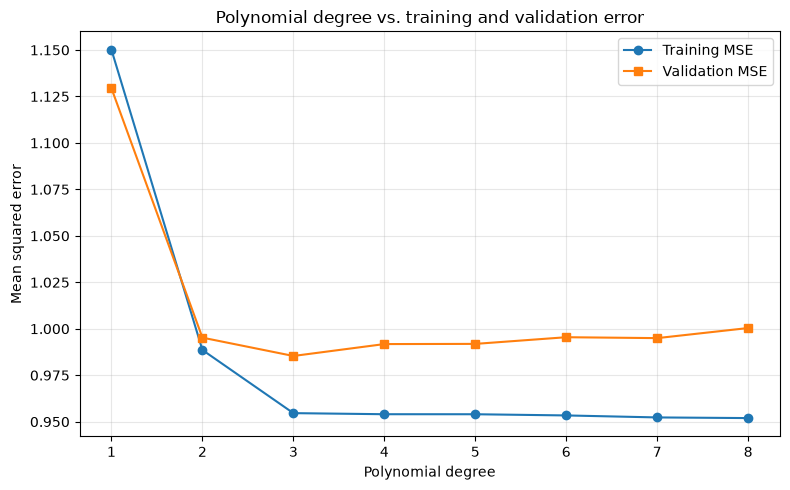

In [51]:
degrees = np.arange(1, 9)

loss_train_list, loss_test_list = polynomial_regression(poly_reg_df, degrees)

# Leave this function's name, and the call to it below, exactly as they are.
# Your figure is marked by hand, and the grader finds it by looking for this
# cell by name -- renaming it hides your plot and there is nothing to mark.
def plot_polynomial_regression(degrees, loss_train_list, loss_test_list):
  """
  Plot the train and test losses of polynomial regression for all d in 'degrees'

  Parameters
  ----------
  degrees: numpy.ndarray of shape (P,)
      List of polynomial degrees that polynomial regression was run on
  loss_train_list: list of length P (number of degrees to try)
      List of training losses for polynomial regression for all degrees
  loss_test_list: list of length P (number of degrees to try)
      List of testing losses for polynomial regression for all degrees

  Returns
  -------
  Nothing
  """

  # STUDENT TODO START:
  # Plot the polynomial degrees (x-axis) against loss_train_list (y-axis) and loss_test_list (y-axis) in a single plot, with different colors.
  # Make sure to include x and y axis labels, legend, as well as the title
  plt.figure(figsize=(8, 5))
  plt.plot(degrees, loss_train_list, "o-", label="Training MSE")
  plt.plot(degrees, loss_test_list, "s-", label="Validation MSE")
  plt.xlabel("Polynomial degree")
  plt.ylabel("Mean squared error")
  plt.title("Polynomial degree vs. training and validation error")
  plt.xticks(degrees)
  plt.legend()
  plt.grid(alpha=0.3)
  plt.tight_layout()
  plt.show()
  # STUDENT TODO END

plot_polynomial_regression(degrees, loss_train_list, loss_test_list)

## **1.3. Effect of learning rate on gradient descent [5 pts, Manually Graded]**

Marks: **3** for scaling the features and configuring the model as specified, **2** for the
plot and your comment on it.

Run the below cell to download the dataset.

In [52]:
if not os.path.exists("cis5190_hw1_admit.csv"):
    !wget https://raw.githubusercontent.com/CIS5190/cis-4190-5190-fall-26/main/hw1/cis5190_hw1_admit.csv

train_df = pd.read_csv("cis5190_hw1_admit.csv")

The dataset contains two features - the input is the scores in two exams and the target is whether the student was admitted into a college or not. Your task is to use this dataset and plot the **variation of the cost function with respect to the number of gradient descent iterations for different learning rates**. Perform the following steps:

1. Scale the features using StandardScaler
2. For each of the learning rates in `learning_rates`, fit a linear regression model to the scaled data by running a maximum of 100 iterations of gradient descent with L2 penalty and $\lambda$ as 0.001.
3. Show the variation of the cost (stored in `hist_cost_`) with respect to the number of iterations for all the learning rates in the same plot.
4. In the markdown cell that follows the plot, briefly comment on the effect of increasing the learning rate, and which of these rates you would pick based on what you see.

In [53]:
from sklearn.preprocessing import StandardScaler

learning_rates = [0.001, 0.01, 0.03, 0.1, 1.0]

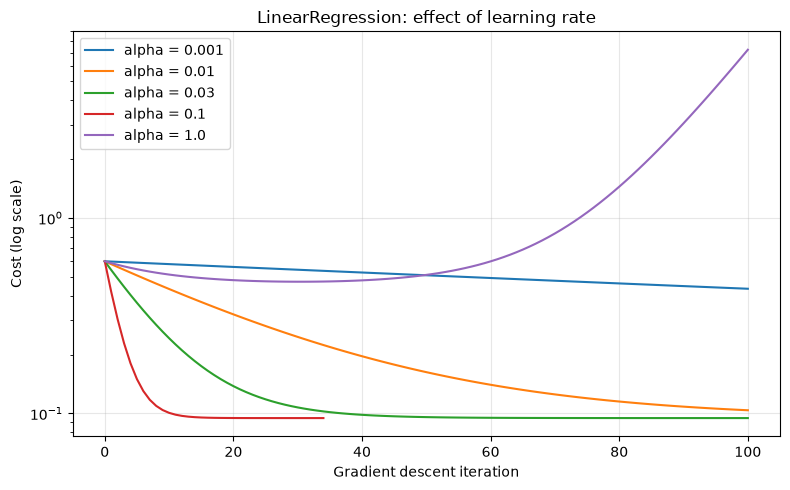

In [54]:
# Leave this function's name, and the call to it below, exactly as they are.
# Your figure is marked by hand, and the grader finds it by looking for this
# cell by name -- renaming it hides your plot and there is nothing to mark.
def plot_lr_cost_var(train_df, learning_rates):
  """
  For each learning rate in learning_rates, plot the variations in cost for a
  Linear Regression model with that learning rate plus other settings specified above.

  Parameters
  ----------
  train_df: numpy.ndarray of shape (N, D + 1)
      Dataset with features and output labels
  learning_rates: list of length L (number of learning rates to try)
      List of learning rates to run Linear Regression with

  Returns
  -------
  Nothing
  """
  # STUDENT TODO START:
  X = StandardScaler().fit_transform(train_df.iloc[:, :-1].values)
  y = train_df.iloc[:, -1].values
  plt.figure(figsize=(8, 5))
  for alpha in learning_rates:
      model = LinearRegression(alpha=alpha, max_iter=100, penalty="l2", lambd=0.001)
      model.fit(X, y)
      plt.plot(np.arange(len(model.hist_cost_)), model.hist_cost_, label=f"alpha = {alpha}")
  plt.xlabel("Gradient descent iteration")
  plt.ylabel("Cost (log scale)")
  plt.yscale("log")
  plt.title("LinearRegression: effect of learning rate")
  plt.legend()
  plt.grid(alpha=0.3)
  plt.tight_layout()
  plt.show()
  # STUDENT TODO END

plot_lr_cost_var(train_df, learning_rates)

**Your comment (1.3):**

*Replace this italic line with a sentence or two on what increasing the learning rate does to
the cost curves, and which of these rates you would pick. Leave the bold heading above this
line exactly as it is — it is how your answer is found and shown to whoever marks it.*

<!-- STUDENT TODO START: -->
Increasing the learning rate from 0.001 to 0.1 speeds up convergence: alpha = 0.1 reaches a cost of about 0.09464 within 100 iterations, while alpha = 0.001 is still near 0.43414. I would choose 0.1; alpha = 1.0 is unstable and its cost eventually increases to about 7.25.
<!-- STUDENT TODO END -->


## **1.4. Synthetic dataset [ungraded]**

In this section we will first create some synthetic data on which we will run your linear regression implementation. We are creating 100 data points around the function $y = mx + b$, introducing Gaussian noise.

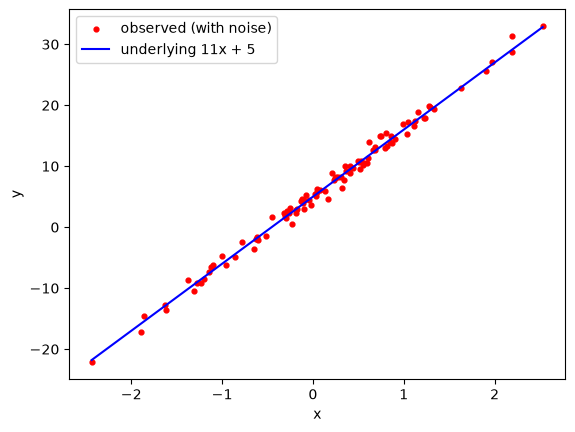

In [55]:
# Don't modify this cell
num_samples = 100

np.random.seed(1)
noise = np.random.randn(num_samples, 1)
X = np.random.randn(num_samples, 1)

y_ideal = 11*X + 5
y_real = (11*X + 5) + noise

# X is unsorted, so plot the line in x-order rather than array order.
order = np.argsort(X[:, 0])
plt.scatter(X, y_real, c='r', s=12, label='observed (with noise)')
plt.plot(X[order], y_ideal[order], 'b', label='underlying 11x + 5')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


The red points scatter around the line `11x + 5`. That scatter is the whole reason this is a
regression problem rather than solving two equations: your model only ever sees `y_real`, and
has to recover the line underneath it.

Fitting on `y_real`, you should see the training loss fall with the number of iterations and
$\beta$ settle *close to* [b, m] = [5, 11] — close, not exact, because the noise is not
recoverable.

Then compare the three runs below. Both penalties pull $\beta$ away from the least-squares
solution, and neither improves the test MSE by anything meaningful. That is the point of the
comparison: with 100 points, one feature and this little noise there is no overfitting for
regularization to prevent, so all a penalty can do here is add bias. Ask yourself what would
have to be different about this dataset — how many features, how many points, how much
noise — before L1 or L2 started to earn its keep.

One thing worth checking as you read the numbers: a penalty should *shrink* the norm of
$\beta$, never grow it. If your L1 run grows it instead, go back to the derivative of the L1
term you worked out in 1.1.2 — in particular, whether it depends on each coefficient or not.

Note also where the test MSE bottoms out. It cannot go below the variance of the noise you
added, no matter how good the model is.



 beta: [ 5.00452414 11.09404731] 
 Norm of beta: 12.17058534157273 
 Testing MSELoss: 1.0420991235704287


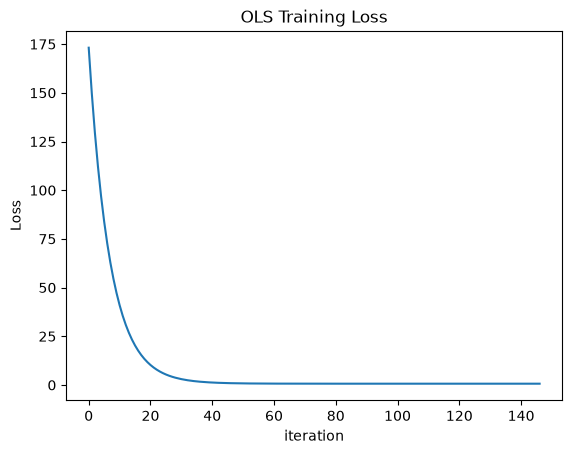


 beta: [ 5.0062499  11.08414804] 
 Norm of beta: 12.162272641470459 
 Testing MSELoss: 1.041571114656125


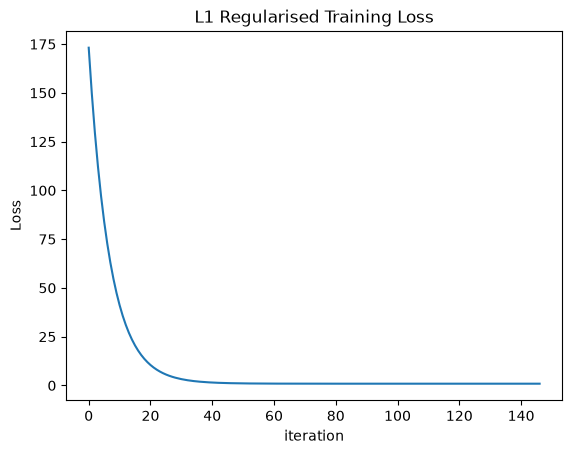


 beta: [ 5.04207242 10.87866891] 
 Norm of beta: 11.99032658368691 
 Testing MSELoss: 1.0545328872701865


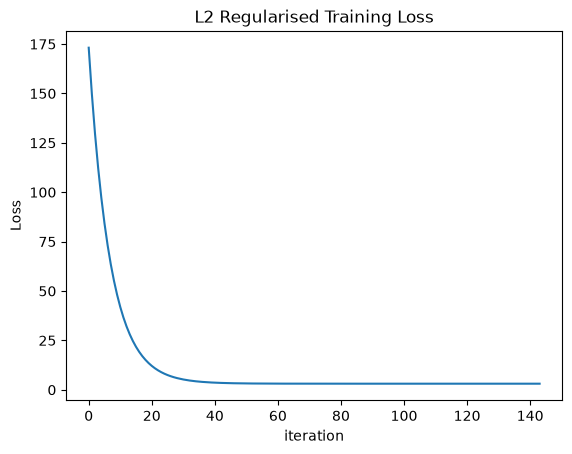

In [56]:
import sklearn.metrics
from sklearn.model_selection import train_test_split

def test_synthetic_data(X, y, n_iter = 2000, penalty=None, lambd=0):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=37)
  # We deliberately do not standardize here: we want beta to come back in the units of the
  # original line, so it can be compared against [5, 11] directly.

  alpha = 0.03  # Learning Rate

  # Train the model
  lr_model = LinearRegression(alpha = alpha, tol=1e-4, max_iter = n_iter, penalty=penalty, lambd=lambd)
  lr_model.fit(X_train, y_train[:, 0])
  y_predict = lr_model.predict(X_test)
  loss = sklearn.metrics.mean_squared_error(y_test, y_predict)
  print()
  print(" beta: {} \n Norm of beta: {} \n Testing MSELoss: {}".format(
      lr_model.beta_, np.linalg.norm(lr_model.beta_, ord=2), loss))

  loss_history = lr_model.hist_cost_
  plt.plot(range(len(loss_history)), loss_history)
  plt.title("OLS Training Loss")
  plt.xlabel("iteration")
  plt.ylabel("Loss")
  if penalty == "l1":
    plt.title("L1 Regularised Training Loss")
  elif penalty == "l2":
    plt.title("L2 Regularised Training Loss")
  plt.show()

# Fit on y_real: the noisy observations are all your model gets to see.
test_synthetic_data(X, y_real, 500)
test_synthetic_data(X, y_real, 500, "l1", 0.02)
test_synthetic_data(X, y_real, 500, "l2", 0.02)


# **2. Logistic Regression [18 pts]**

In Part 1 you implemented linear regression. Logistic regression uses the same machinery —
a cost function, its gradient, and gradient descent — with a different cost and a sigmoid
applied to the model's output, so that it predicts a probability of belonging to class 1
rather than a real-valued target.

You may not use `sklearn` (or any other library that fits a model for you) to implement the
class below; `numpy` is what you need. You are welcome to use `sklearn` afterwards to check
your own results.


## **2.1. Logistic Regression Implementation [16 pts, Autograded]**

Implement logistic regression with both L1 and L2 regularization by completing the
`LogisticRegression` class.

Your class must implement the following API:

* `__init__(alpha, tol, max_iter, beta_init, penalty, lambd)`
* `sigmoid(x)`
* `compute_cost(beta, X, y)`
* `compute_gradient(beta, X, y)`
* `has_converged(beta_old, beta_new)`
* `fit(X, y)`
* `predict_proba(X)`
* `predict(X)`

Note that these methods have already been declared for you (with the correct signatures) in the
`LogisticRegression` class below. **DO NOT** change the API.

---

### **2.1.1. Sigmoid Function [1 pt]**

You should begin by implementing the `sigmoid` function. The sigmoid function $\sigma(x)$ is
defined as:

> $\sigma(x) = \frac{1}{1\ +\ \text{exp}(-x)}$

**Be certain that your sigmoid function works with both vectors and matrices** --- for either a
vector or a matrix, your function should apply the sigmoid to every element.

---

### **2.1.2. Cost Function [3 pts]**

The `compute_cost` function should compute the cost for a given $\beta$ vector. The cost is a
scalar value given by:

> $
L({\beta}) = -\sum_{i =1}^N [ y_i\log(f_{{\beta}}({x}_i)) + (1 - y_i)\log(1 - f_{{\beta}}({x}_i))]
$

where
> $
f_{\beta}(x_{i}) = \sigma(\beta^{T}x_{i})
$

L1 Regularization Loss:
>$
L1({\beta}) = L({\beta}) + \lambda \sum_{j = 1}^D  |{\beta}_j|
$

L2 Regularization Loss:
>$
L2({\beta}) = L({\beta}) + \lambda \sum_{j = 1}^D  {\beta}_j^2
$

$N$ is the number of training samples and $D$ is the number of features (excluding the
intercept term). $\beta$ is a $D + 1$ dimensional vector, with the first element (index $j=0$)
being the intercept term. **Note that we do not include the intercept in the regularization
terms.**

> **Clarification — this differs from lecture.** Lecture writes the negative log-likelihood
> as a **mean** over the training set:
>
> $
> \mathcal{L}({\beta}; Z) = -\frac{1}{n}\sum_{i=1}^{n} [ y_i\log(\sigma(\beta^{T}x_i)) + (1 - y_i)\log(1 - \sigma(\beta^{T}x_i))]
> $
>
> For this homework we use the **sum** form instead — the same expression *without* the
> $1/n$ term, as written above (lecture's $n$ is this notebook's $N$). The two differ only by
> that constant factor and have the same minimizer, but the autograder compares values, so
> implement the sum form. The regularization terms above are not scaled by $N$ either.
>
> The gradient in 2.1.3 carries no $1/N$ either. Part 1 is unaffected — the mean-squared
> error in 1.1.1 *is* an average, as in lecture.

---

### **2.1.3. Gradient of the Cost Function [3 pts]**

The `compute_gradient` function should compute the gradient of the cost function at a given
$\beta$.

**Deriving it is part of the exercise** — as in part 1, the formula is not given to you.
Differentiate the cost from 2.1.2, penalty included, and remember that the intercept
$\beta_0$ is excluded from the penalty there, so it must be excluded from its derivative too.

As in 2.1.2, there is no $1/N$ factor here: differentiate the cost exactly as it is written
above.

Hint: use the dot product function `np.dot` or `.dot()` to compute gradients efficiently.

---

### **2.1.4. Convergence Check [1 pt]**

The `has_converged` function should return whether the gradient descent algorithm has
converged. Refer to *Section 2.1.5* below for the convergence condition.

---

### **2.1.5. Training [4 pts]**

The `fit` method should train the model via gradient descent, relying on the cost and gradient
functions. The trained weights/coefficients must be stored as `beta_`. The weights start as a
zero vector. The weights and the corresponding cost after every gradient descent iteration must
be stored in `hist_beta_` and `hist_cost_` respectively.

* The gradient descent stops or converges when $\beta$ stops changing or changes negligibly
between consecutive iterations, i.e., when
$\| {\beta}_\mathit{new} -  {\beta}_\mathit{old} \|_2 \leq \epsilon$,
for some small $\epsilon$ (e.g., $\epsilon$ = 1E-4). $\epsilon$ is stored as `tol` (short for
tolerance).

* To ensure that the function terminates, we set a maximum limit on the number of gradient
descent iterations irrespective of whether $\beta$ converges. The limit is stored as
`max_iter`.

* `alpha` is the learning rate of the gradient descent algorithm.

---

### **2.1.6. Predict Probability [2 pts]**

The `predict_proba` function should predict the probabilities that the data points in a given
input data matrix belong to class 1.

---

### **2.1.7. Predict [2 pts]**

The `predict` function should predict the classes of the data points in a given input data
matrix.

---

### **Implementation Diagram**
```plaintext

 ┌───────────────────────────────────────────┐
 | __init__(alpha, tol, max_iter, beta_init,   |
 |          penalty, lambd)                    |
 └───────────────────────────────────────────┘
                       │
                       ▼
 ┌───────────────────────────────────────────┐
 | fit(X, y)                                   |
 |  Loop per-iteration:                        |
 |   - compute_gradient(beta, X, y)            |
 |   - compute_cost(beta, X, y)                |
 |   - has_converged(beta_old, beta_new) ?     |
 └───────────────────────────────────────────┘
                       │
                       ▼
 ┌───────────────────────────────────────────┐
 | predict_proba(X)                            |
 |  - sigmoid(Xβ)                              |
 └───────────────────────────────────────────┘
                       │
                       ▼
 ┌───────────────────────────────────────────┐
 | predict(X)                                  |
 |  - threshold probabilities at 0.5           |
 └───────────────────────────────────────────┘
```


In [57]:
class LogisticRegression:

    """
    Logistic Regression (aka logit, MaxEnt) classifier.

    Parameters
    ----------
    alpha: float, default=0.01
        Learning rate
    tol : float, default=0.0001
        Tolerance for stopping criteria
    max_iter : int, default=10000
        Maximum number of iterations of gradient descent
    beta_init: None (or) numpy.ndarray of shape (D + 1,)
        The initial weights; if None, all weights will be zero by default
    penalty : string, default = None
        The type of regularization. The other acceptable options are l1 and l2
    lambd : float, default = 1.0
        The parameter regularisation constant (i.e. lambda)

    Attributes
    ----------
    beta_ : numpy.ndarray of shape (D + 1,)
        The value of the coefficients after gradient descent has converged
        or the number of iterations hit the maximum limit
    hist_beta_ : numpy.ndarray of shape (num_iter, D + 1) where num_iter is the number of gradient descent iterations
        Stores beta_ after every gradient descent iteration
    hist_cost_ : numpy.ndarray of shape (num_iter,) where num_iter is the number of gradient descent iterations
        Stores cost after every gradient descent iteration

    """

    def __init__(self, alpha=0.01, tol=0.0001, max_iter=10000, beta_init=None, penalty = None, lambd = 1.0):

        self.alpha = alpha
        self.tol = tol
        self.max_iter = max_iter
        self.beta_init = beta_init
        self.penalty = penalty
        self.lambd = lambd
        self.beta_ = None
        self.hist_cost_ = None
        self.hist_beta_ = None

    def get_params(self, deep=True):
        # Lets sklearn utilities read this model's hyperparameters. Nothing in this
        # assignment needs it; leave it as it is.
        return {"alpha": self.alpha, "max_iter": self.max_iter, "lambd" : self.lambd, "penalty" : self.penalty}

    def sigmoid(self, x):

        """
        Compute the sigmoid value of the argument.

        Parameters
        ----------
        x: numpy.ndarray

        Returns
        -------
        out: numpy.ndarray
            The sigmoid value of x
        """

        # Complete the function
        # STUDENT TODO START:
        return np.exp(-np.logaddexp(0, -np.asarray(x, dtype=float)))
        # STUDENT TODO END

    def compute_cost(self, beta, X, y):

        """
        Compute the cost/objective function.

        Parameters
        ----------
        beta: numpy.ndarray of shape (D + 1,)
            The coefficients
        X: numpy.ndarray of shape (N, D + 1)
            The features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        cost: float
            The cost as a scalar value
        """

        # Complete the function (should account for three cases - no penalty, l1 penalty, and l2 penalty)
        # STUDENT TODO START:
        logits = X @ beta
        # Stable binary cross-entropy, summed over samples.
        cost = np.sum(np.logaddexp(0, logits) - y * logits)
        if self.penalty == "l1":
            cost += self.lambd * np.sum(np.abs(beta[1:]))
        elif self.penalty == "l2":
            cost += self.lambd * np.sum(beta[1:] ** 2)
        return float(cost)
        # STUDENT TODO END

    def compute_gradient(self, beta, X, y):

        """
        Compute the gradient of the cost function. Hint: Use the dot product function np.dot or .dot() to compute gradients efficiently.

        Parameters
        ----------
        beta: numpy.ndarray of shape (D + 1,)
            The coefficients
        X: numpy.ndarray of shape (N, D + 1)
            The features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        gradient: numpy.ndarray of shape (D + 1,)
            The gradient values
        """

        # Complete the function (should account for three cases - no penalty, l1 penalty, and l2 penalty)
        # STUDENT TODO START:
        gradient = X.T @ (self.sigmoid(X @ beta) - y)
        if self.penalty == "l1":
            gradient[1:] += self.lambd * np.sign(beta[1:])
        elif self.penalty == "l2":
            gradient[1:] += 2 * self.lambd * beta[1:]
        return gradient
        # STUDENT TODO END

    def has_converged(self, beta_old, beta_new):

        """
        Return whether gradient descent has converged.

        Parameters
        ----------
        beta_old: numpy.ndarray of shape (D + 1,)
            The weights prior to the update by gradient descent
        beta_new: numpy.ndarray of shape (D + 1,)
            The weights after the update by gradient descent

        Returns
        -------
        converged: bool
            Whether gradient descent converged or not
        """

        # Complete the function
        # STUDENT TODO START:
        return bool(np.linalg.norm(beta_new - beta_old) <= self.tol)
        # STUDENT TODO END

    def fit(self, X, y):

        """
        Compute the coefficients using gradient descent and store them as beta_.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The features matrix
        y: numpy.ndarray of shape (N,)
            The target variable array

        Returns
        -------
        Nothing
        """

        N, D = X.shape

        # Adding a column of ones at the beginning for the bias term
        ones_col = np.ones((N, 1))
        X = np.hstack((ones_col, X))

        # Initializing the weights
        if self.beta_init is None:
            beta_old = np.zeros((D + 1,))
        else:
            beta_old = self.beta_init

        # Initializing the historical weights matrix
        # Remember to append this matrix with the weights after every gradient descent iteration
        self.hist_beta_ = np.array([beta_old])

        # Computing the cost for the initial weights
        cost = self.compute_cost(beta_old, X, y)

        # Initializing the historical cost array
        # Remember to append this array with the cost after every gradient descent iteration
        self.hist_cost_ = np.array([cost])

        # Complete the function
        # STUDENT TODO START:
        weights = [beta_old.copy()]
        costs = [cost]
        for _ in range(self.max_iter):
            beta_new = beta_old - self.alpha * self.compute_gradient(beta_old, X, y)
            weights.append(beta_new.copy())
            costs.append(self.compute_cost(beta_new, X, y))
            converged = self.has_converged(beta_old, beta_new)
            beta_old = beta_new
            if converged:
                break
        self.beta_ = beta_old.copy()
        self.hist_beta_ = np.array(weights)
        self.hist_cost_ = np.array(costs)
        # STUDENT TODO END

    def predict_proba(self, X):

        """
        Predict the probabilities that the data points in X belong to class 1.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The features matrix

        Returns
        -------
        y_hat: numpy.ndarray of shape (N,)
            The predicted probabilities that the data points in X belong to class 1
        """

        N = X.shape[0]
        X = np.hstack((np.ones((N, 1)), X))

        # Complete the function
        # STUDENT TODO START:
        return self.sigmoid(X @ self.beta_)
        # STUDENT TODO END

    def predict(self, X):

        """
        Predict the classes of the data points in X.

        Parameters
        ----------
        X: numpy.ndarray of shape (N, D)
            The features matrix

        Returns
        -------
        y_pred: numpy.ndarray of shape (N,)
            The predicted class of the data points in X
        """

        # Complete the function
        # STUDENT TODO START:
        return (self.predict_proba(X) >= 0.5).astype(int)
        # STUDENT TODO END

In [58]:
def test_log_reg_sigmoid(StudentLogisticRegression):

    student_lr_clf = StudentLogisticRegression()
    test_case = np.array([ 1.62434536, -0.61175641, -0.52817175, -1.07296862,  0.86540763])
    student_ans = student_lr_clf.sigmoid(test_case)
    required_ans = np.array([0.83539354, 0.35165864, 0.3709434 , 0.25483894, 0.70378922])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_log_reg_sigmoid(LogisticRegression)

In [59]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_sigmoid', answer = grader_serialize(LogisticRegression))


Correct! You earned 1/1 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [60]:
def test_log_reg_compute_cost(StudentLogisticRegression):

    test_case_beta = np.array([ 1.62434536, -0.61175641])
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])

    student_lr_clf = StudentLogisticRegression()
    student_ans = student_lr_clf.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 7.467975765663204

    assert np.abs(student_ans - required_ans) <= 1e-2

    student_lr_clf = StudentLogisticRegression(penalty="l1", lambd=0.1)
    student_ans = student_lr_clf.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 7.52915138076548

    assert np.abs(student_ans - required_ans) <= 1e-2

    student_lr_clf = StudentLogisticRegression(penalty="l2", lambd=0.1)
    student_ans = student_lr_clf.compute_cost(test_case_beta, test_case_X, test_case_y)
    required_ans = 7.505400330283089
    assert np.abs(student_ans - required_ans) <= 1e-2

test_log_reg_compute_cost(LogisticRegression)

In [61]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_compute_cost', answer = grader_serialize(LogisticRegression))


Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [62]:
def test_log_reg_compute_gradient(StudentLogisticRegression):

    test_case_beta = np.array([ 1.62434536, -0.61175641])
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])

    student_lr_clf = StudentLogisticRegression()
    student_ans = student_lr_clf.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = np.array([ 2.60573737, -2.20203139])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

    student_lr_clf = StudentLogisticRegression(penalty="l1", lambd=0.1)
    student_ans = student_lr_clf.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = np.array([ 2.60573737, -2.30203139])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

    student_lr_clf = StudentLogisticRegression(penalty="l2", lambd=0.1)
    student_ans = student_lr_clf.compute_gradient(test_case_beta, test_case_X, test_case_y)
    required_ans = np.array([ 2.60573737, -2.32438267])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_log_reg_compute_gradient(LogisticRegression)

In [63]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_compute_gradient', answer = grader_serialize(LogisticRegression))


Correct! You earned 3/3 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [64]:
def test_log_reg_has_converged(StudentLogisticRegression):

    student_lr_clf = StudentLogisticRegression()
    test_case_beta_old = np.array([ 1.62434536, -0.61175641])
    test_case_beta_new = np.array([1.624345, -0.611756])
    student_ans = student_lr_clf.has_converged(test_case_beta_old, test_case_beta_new)
    required_ans = True

    assert student_ans == required_ans

test_log_reg_has_converged(LogisticRegression)

In [65]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_has_converged', answer = grader_serialize(LogisticRegression))


Correct! You earned 1/1 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [66]:
def test_log_reg_fit(StudentLogisticRegression):

    student_lr_clf = StudentLogisticRegression(max_iter=5)
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])
    student_lr_clf.fit(test_case_X, test_case_y)
    student_ans = student_lr_clf.hist_beta_
    required_ans = np.array([[ 0.        ,  0.        ,  0.        ],
                             [ 0.005     , -0.00597503,  0.00564325],
                             [ 0.01006813, -0.01184464,  0.0111865 ],
                             [ 0.01520121, -0.01761226,  0.01663348],
                             [ 0.02039621, -0.02328121,  0.02198778],
                             [ 0.02565018, -0.0288547 ,  0.02725288]])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_log_reg_fit(LogisticRegression)

In [67]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_fit', answer = grader_serialize(LogisticRegression))


Correct! You earned 4/4 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [68]:
def test_log_reg_predict_proba(StudentLogisticRegression):

    student_lr_clf = StudentLogisticRegression(max_iter=5)
    test_case_X = np.array([[ 1.62434536, -0.61175641],
                            [-0.52817175, -1.07296862],
                            [ 0.86540763, -2.3015387 ],
                            [ 1.74481176, -0.7612069 ],
                            [ 0.3190391,  -0.24937038]])
    test_case_y = np.array([1, 1, 0, 0, 1])
    student_lr_clf.fit(test_case_X, test_case_y)
    student_ans = student_lr_clf.predict_proba(test_case_X)
    required_ans = np.array([0.49052814, 0.5029122 , 0.48449386, 0.48864172, 0.50241207])

    assert np.linalg.norm(student_ans - required_ans) <= 1e-2

test_log_reg_predict_proba(LogisticRegression)

In [69]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_predict_proba', answer = grader_serialize(LogisticRegression))


Correct! You earned 2/2 points. You are a star!

Your submission has been successfully recorded in the gradebook.


In [70]:
def test_log_reg_predict(StudentLogisticRegression):

    student_lr_clf = StudentLogisticRegression(max_iter=5)
    np.random.seed(1)
    test_case_X = np.random.randn(50, 2)
    test_case_y = np.random.randint(0, 2, 50)
    student_lr_clf.fit(test_case_X, test_case_y)
    student_ans = student_lr_clf.predict(test_case_X)
    required_ans = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
                             0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1])

    assert np.mean(np.abs(student_ans - required_ans)) <= 0.02

test_log_reg_predict(LogisticRegression)

In [71]:
# PennGrader Grading Cell
grader.grade(test_case_id = 'test_log_reg_predict', answer = grader_serialize(LogisticRegression))


Correct! You earned 2/2 points. You are a star!

Your submission has been successfully recorded in the gradebook.


## **2.2. Effect of learning rate on gradient descent [2 pts, Manually Graded]**

Marks: **1** for scaling the features and configuring the model as specified, **1** for the
plot and your comment on it.


This is the same dataset you used in 1.3 — two exam scores as the input, and whether the
student was admitted as the target. There you fitted it with linear regression; here you fit
the same data with the classifier you just wrote, which is what the target actually calls for.

Plot the variation of the cost function with respect to the number of gradient descent
iterations for different learning rates. Perform the following steps:

1. Scale the features using `StandardScaler`
2. For each of the learning rates in `learning_rates`, fit a `LogisticRegression` to the scaled
   data by running a maximum of **100 iterations** of gradient descent with **L2 penalty** and
   **$\lambda$ as 0.001**.
3. Show the variation of the cost (stored in `hist_cost_`) with respect to the number of
   iterations for all the learning rates in the same plot. Give it a title, axis labels and a
   legend.
4. In the markdown cell that follows the plot, briefly comment on the effect of increasing the
   learning rate, and which of these rates you would pick based on what you see.


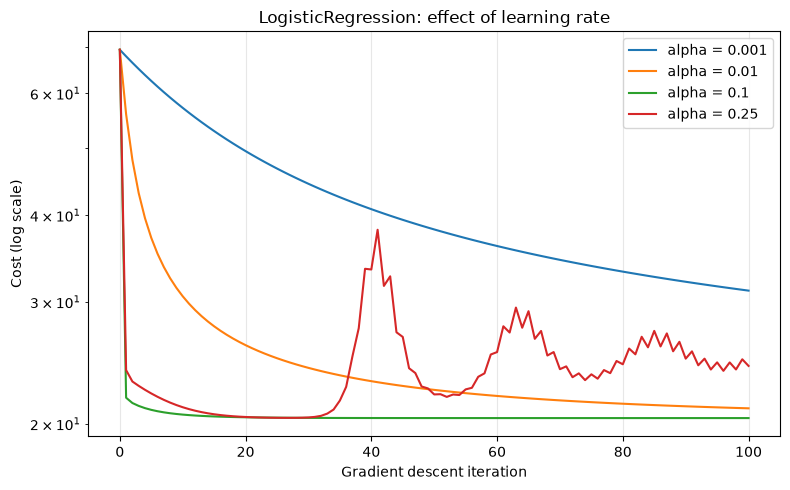

In [72]:
from sklearn.preprocessing import StandardScaler

# train_df was loaded in 1.3; it is the same dataset.
learning_rates = [0.001, 0.01, 0.1, 0.25]

# Leave this function's name, and the call to it below, exactly as they are.
# Your figure is marked by hand, and the grader finds it by looking for this
# cell by name -- renaming it hides your plot and there is nothing to mark.
def plot_logreg_lr_cost(train_df, learning_rates):
  """
  For each learning rate, plot how the cost of a LogisticRegression changes over
  gradient descent iterations, all on one set of axes.

  Parameters
  ----------
  train_df: pandas.DataFrame
      The dataset, with the target in the last column
  learning_rates: list of length L
      The learning rates to try

  Returns
  -------
  Nothing
  """
  # STUDENT TODO START:
  X = StandardScaler().fit_transform(train_df.iloc[:, :-1].values)
  y = train_df.iloc[:, -1].values
  plt.figure(figsize=(8, 5))
  for alpha in learning_rates:
      model = LogisticRegression(alpha=alpha, max_iter=100, penalty="l2", lambd=0.001)
      model.fit(X, y)
      plt.plot(np.arange(len(model.hist_cost_)), model.hist_cost_, label=f"alpha = {alpha}")
  plt.xlabel("Gradient descent iteration")
  plt.ylabel("Cost (log scale)")
  plt.yscale("log")
  plt.title("LogisticRegression: effect of learning rate")
  plt.legend()
  plt.grid(alpha=0.3)
  plt.tight_layout()
  plt.show()
  # STUDENT TODO END

plot_logreg_lr_cost(train_df, learning_rates)


**Your comment (2.2):**

*Replace this italic line with a sentence or two on what increasing the learning rate does to
the cost curves here, and which of these rates you would pick. Leave the bold heading above
this line exactly as it is — it is how your answer is found and shown to whoever marks it.*

<!-- STUDENT TODO START: -->
Increasing the learning rate from 0.001 to 0.1 reduces the cost faster, with alpha = 0.1 reaching about 20.38 after 100 iterations. I would choose 0.1; alpha = 0.25 produces oscillations and finishes at a higher cost of about 24.24.
<!-- STUDENT TODO END -->


# **Before You Submit: Two Short Reports [4 pts, Autograded]**

These two cells are worth **2 points each**, and the points are for *answering*,
not for any particular answer. There is no answer that scores better than
another: reporting that you used no AI earns full marks, and so does reporting
that you used a lot of it.

We use the responses to calibrate how long assignments actually take and to
understand how students are using AI tools.


### **1. Use of AI tools [2 pts]**

Report any use of AI tools (ChatGPT, Claude, Copilot, Gemini, Cursor, etc.) while
working on this assignment: which ones, how you used them, and whether they helped
or got in the way of understanding the material.

**Being honest here will not cost you points.** Writing `"none"` earns full marks,
and so does describing heavy use. We are trying to learn what actually helps people
learn, which only works if the reports are accurate.


In [73]:
# Replace the empty string with your answer. Anything you write earns full marks --
# including "none". A few sentences is plenty.
AI_USE = ""


# STUDENT TODO START:
AI_USE = "I used OpenAI Codex to implement the TODO sections, generate plots, and check the implementations against the provided local tests and numerical gradients. Codex also drafted the learning-rate comments from the computed results."
# STUDENT TODO END

# PennGrader grading command
grader.grade('test_ai_use_report', AI_USE)


Correct! You earned 2/2 points. You are a star!

Your submission has been successfully recorded in the gradebook.


### **2. Time spent [2 pts]**

Roughly how long did this assignment take you, and how was that time split across
the parts? Rough numbers are genuinely useful — please do not agonize over precision.

You will get a far better estimate if you jot this down **as you go** rather than
reconstructing it at the end.


In [76]:
# Replace the empty string with your answer. Anything you write earns full marks.
# For example: "about 5 hours -- 3 on part 1, 1.5 on part 2, the rest on setup".
TIME_SPENT_HOURS = "about 5 hours -- 3 on part 1, 2 on part 2"


# PennGrader grading command
grader.grade('test_time_report', TIME_SPENT_HOURS)


Correct! You earned 2/2 points. You are a star!

Your submission has been successfully recorded in the gradebook.


# **Submit to Gradescope**

Congratulations on completing the HW1 coding assignment!

**Before you download — check your figures and comments are there.** Sections 1.2, 1.3
and 2.2 are marked by hand from the plots in this notebook, and 1.3 and 2.2 from the
comment you write underneath each one. Scroll back and make sure every plot is showing
and every comment cell has your own words in it. A notebook downloaded with its outputs
cleared arrives with nothing to mark in those sections, and those points are a quarter
of this assignment.

The final step is to download this iPython notebook and submit it to [Gradescope](https://www.gradescope.com).

*To download the notebook from Google Colab, click*
`File` → `Download` → `Download .ipynb`
